In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
sales_data = pd.read_csv("ecommerce_sales.csv")
sales_data.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [4]:
total_revenue = sales_data['revenue'].sum()
print(f"Total Revenue: Rs. {total_revenue:,.2f}")

Total Revenue: Rs. 5,109,775.74


The total revenue represents the sum of revenue generated from all orders in the dataset.

In [5]:
total_orders = sales_data['order_id'].nunique()
print(f"Total Orders: {total_orders}")

Total Orders: 5000


In [6]:
unique_customers = sales_data['customer_id'].nunique()
print(f"There are {unique_customers} unique customers.")

There are 989 unique customers.


In [7]:
average_revenue_per_order = total_revenue/total_orders


In [8]:
total_quantity_sold = sales_data['quantity'].sum()


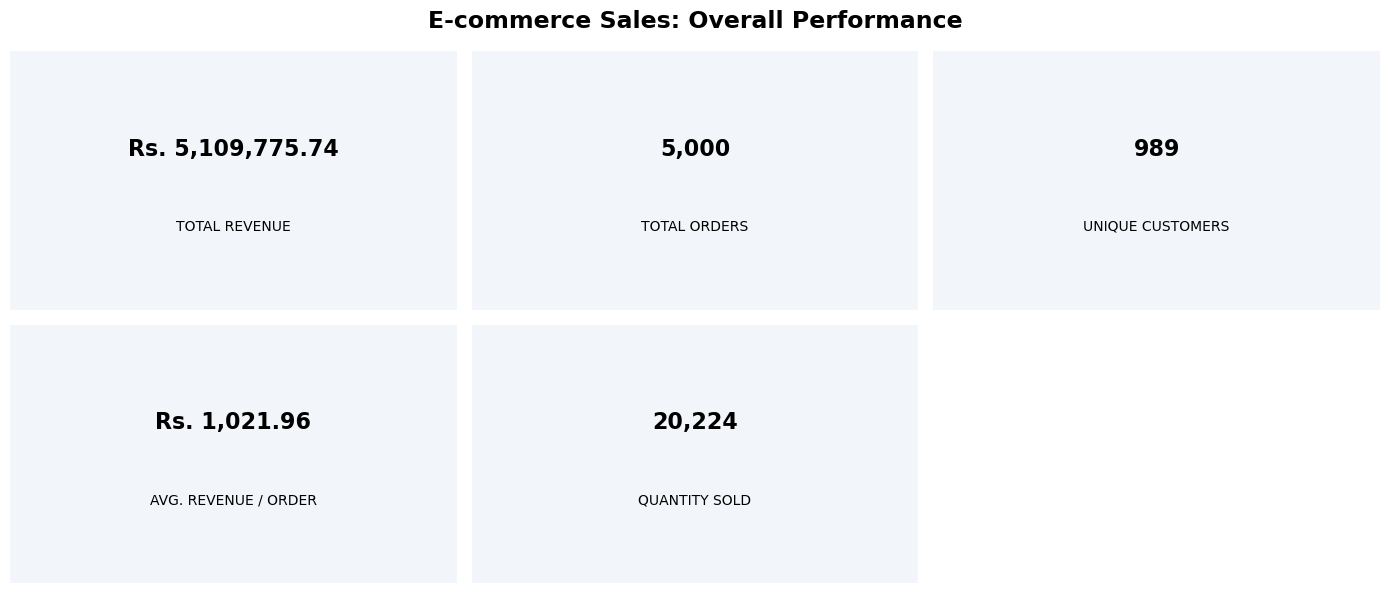

In [9]:


# Create KPI values
kpis = [
    ("TOTAL REVENUE", f"Rs. {total_revenue:,.2f}"),
    ("TOTAL ORDERS", f"{total_orders:,}"),
    ("UNIQUE CUSTOMERS", f"{unique_customers:,}"),
    ("AVG. REVENUE / ORDER", f"Rs. {average_revenue_per_order:,.2f}"),
    ("QUANTITY SOLD", f"{total_quantity_sold:,}")
]

fig,axes = plt.subplots(2,3,figsize=(14,6))
axes = axes.flatten()

for i, (title, value) in enumerate(kpis):
    axes[i].set_facecolor("#F2F5F9")
    axes[i].text(
        0.5, 0.62, value,
        ha="center", va="center",
        fontsize=16, fontweight="bold",
        transform=axes[i].transAxes
    )
    axes[i].text(
        0.5, 0.32, title,
        ha="center", va="center",
        fontsize=10,
        transform=axes[i].transAxes
    )

    axes[i].set_xticks([])
    axes[i].set_yticks([])

    for spine in axes[i].spines.values():
        spine.set_visible(False)

# Hide the unused sixth card
axes[5].axis("off")

fig.suptitle(
    "E-commerce Sales: Overall Performance",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


The summary of KPIs gives a brief description of the performance of the e-commerce business. The total revenue shows the income generated; total orders and unique customers represents sales activity, average revenue per order shows the income per transaction, while the total quantity sold shows the number of products sold.

### OVERALL SALES ANALYSIS

In [10]:
revenue_by_category = sales_data.groupby('product_category')['revenue'].sum().round(2).sort_values(ascending=False)
revenue_by_category

product_category
Electronics    1829899.22
Clothing       1531931.72
Home            982083.92
Beauty          765860.88
Name: revenue, dtype: float64

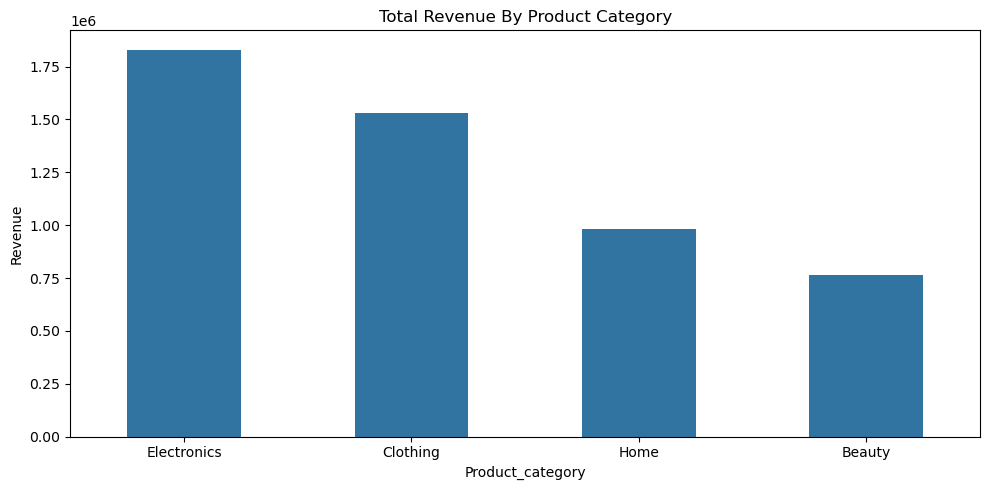

In [39]:
plt.figure(figsize=(10,5))
sns.barplot(x=revenue_by_category.index,y=revenue_by_category.values,width=0.5)
plt.title('Total Revenue By Product Category')
plt.xlabel('Product_category')
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

Electronics product generated the highest revenue, followed by clothing. Home and Beauty contributed less to revenue compared to the other two categories, with Beauty having the lowest sales revenue.This shows that Electronics is performing well, while the business could explore ways to improve sales in the Beauty category.

In [12]:
sales_data.order_date = pd.to_datetime(sales_data.order_date )

In [13]:
monthly_revenue = (
    sales_data.groupby(sales_data['order_date'].dt.month)['revenue']
    .sum()
    .sort_index()
)
monthly_revenue

order_date
1     426374.92
2     413890.24
3     425050.52
4     398715.16
5     479772.55
6     442941.58
7     440570.72
8     460874.78
9     402368.11
10    407873.12
11    410657.88
12    400686.16
Name: revenue, dtype: float64

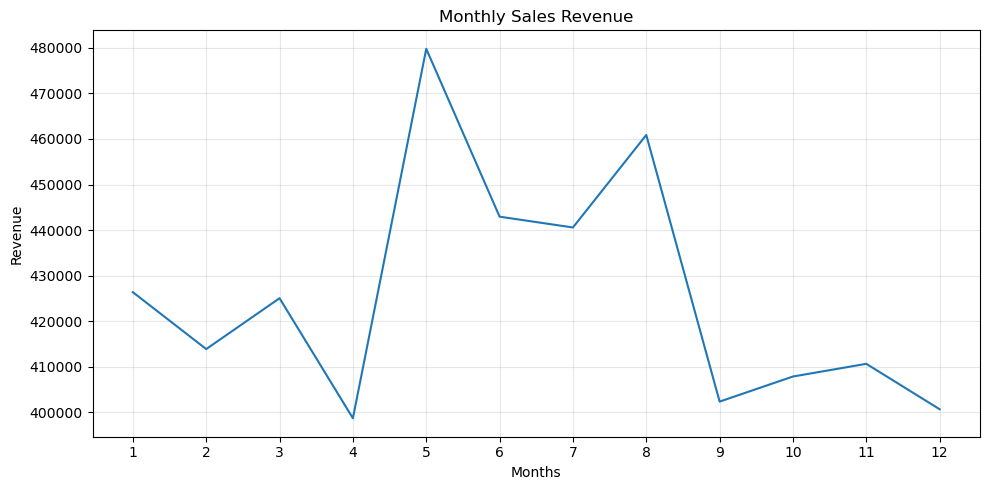

In [14]:
plt.figure(figsize=(10,5))
sns.lineplot(monthly_revenue)
plt.title("Monthly Sales Revenue")
plt.xlabel('Months')
plt.ylabel('Revenue')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

May generated the highest revenue, followed by August, while April had the lowest revenue. This shows that sales revenue varied from month to month. The business can look at what made May more successful and use those findings to improve sales during months with lower revenue.

In [15]:
Yearly_sales_revenue = sales_data.groupby(sales_data['order_date'].dt.year)['revenue'].sum().sort_values(ascending=False)
Yearly_sales_revenue

order_date
2033    408725.72
2030    387884.46
2032    386584.63
2026    386369.69
2027    386151.91
2028    376844.80
2022    371824.30
2023    365915.79
2031    365250.83
2034    363239.55
2024    363209.13
2029    359239.24
2025    349802.33
2035    238733.36
Name: revenue, dtype: float64

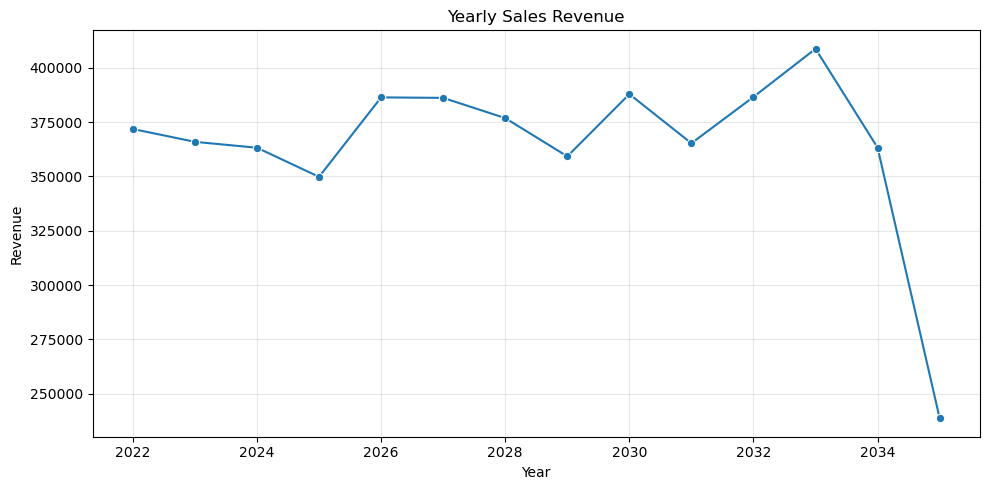

In [22]:
plt.figure(figsize=(10,5))
sns.lineplot(Yearly_sales_revenue,marker='o')
plt.title('Yearly Sales Revenue')
plt.xlabel('Year')
plt.ylabel('Revenue')
plt.tight_layout()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Yearly sales revenue went up and down over the years instead of showing steady growth. Revenue was highest in 2033 and lowest in 2035. The drop in revenue in 2035 suggests that the business should look into possible reasons for the decline and find ways to improve sales.

In [17]:
monthly_orders = (
    sales_data.groupby(sales_data['order_date'].dt.month)['order_id']
    .nunique()
    .sort_index()
)
monthly_orders

order_date
1     434
2     395
3     434
4     420
5     434
6     420
7     434
8     434
9     399
10    403
11    390
12    403
Name: order_id, dtype: int64

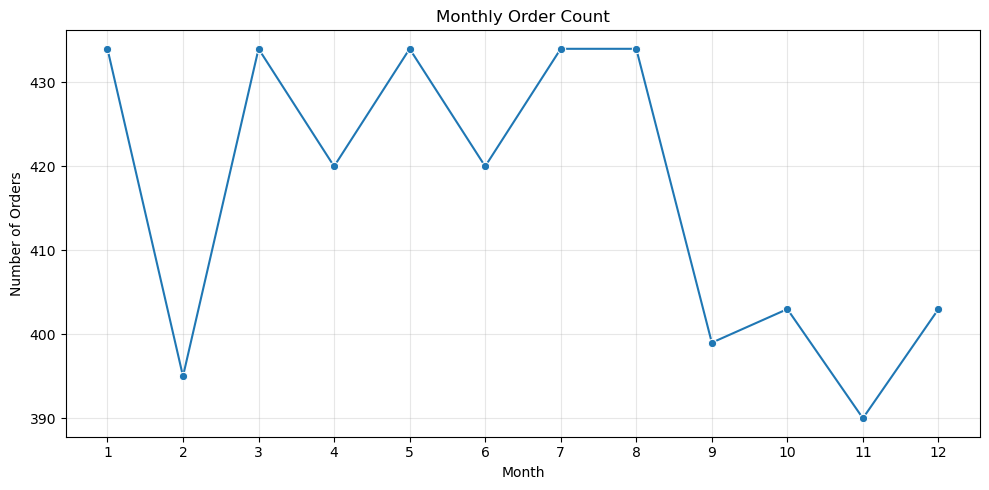

In [18]:
plt.figure(figsize=(10, 5))
sns.lineplot(x=monthly_orders.index, y=monthly_orders.values, marker='o')
plt.title('Monthly Order Count')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


January, March, May, July, and August had the highest number of orders, with 434 orders each. November had the fewest orders, with 390. Overall, the number of orders was fairly stable throughout the year, although November had slightly lower sales activity than the other months.

In [19]:
# plt.figure(figsize=(10,5))
# plt.title('Monthly Order Count')
# sns.barplot(x=monthly_orders.index,y=monthly_orders.values)
# plt.xlabel('Months')
# plt.ylabel('Number of orders')
# plt.tight_layout()
# plt.show()

### PRODUCT CATEGORY ANALYSIS

#### Which product category generates highest revenue?

In [23]:
revenue_by_category = sales_data.groupby('product_category')['revenue'].sum().sort_values(ascending=False)
revenue_by_category

product_category
Electronics    1829899.22
Clothing       1531931.72
Home            982083.92
Beauty          765860.88
Name: revenue, dtype: float64

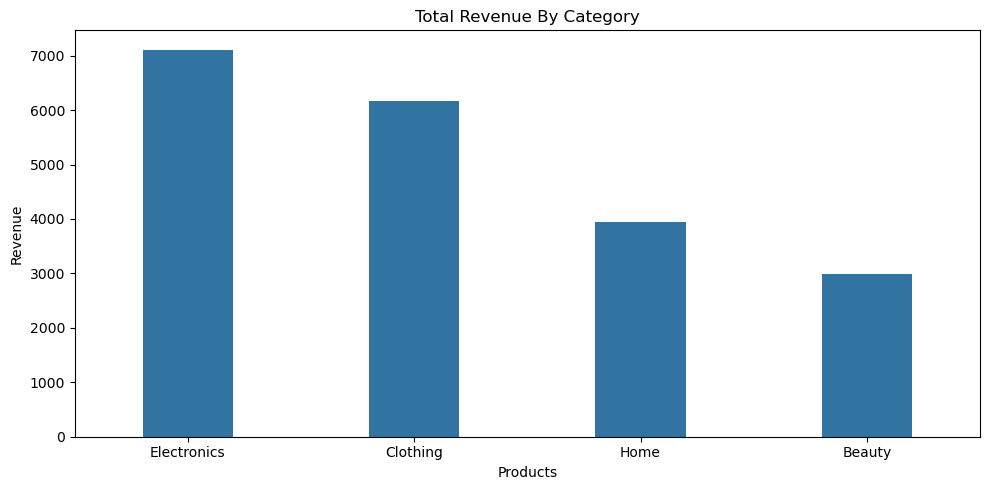

In [103]:
plt.figure(figsize=(10,5))
sns.barplot(x=revenue_by_category.index,y=revenue_by_category.values,width=0.4)
plt.title('Total Revenue By Category')
plt.xlabel('Products')
plt.ylabel('Revenue')
plt.tight_layout()
plt.show()

Electronics product generated the highest revenue, followed by clothing. Home and Beauty contributed less to revenue compared to the other two categories, with Beauty having the lowest sales revenue.This shows that Electronics is performing well, while the business could explore ways to improve sales in the Beauty category.

#### Which category sells the most quantity?

In [98]:
quantity_by_category = sales_data.groupby('product_category')['quantity'].sum().sort_values(ascending=False)
quantity_by_category

product_category
Electronics    7109
Clothing       6171
Home           3949
Beauty         2995
Name: quantity, dtype: int64

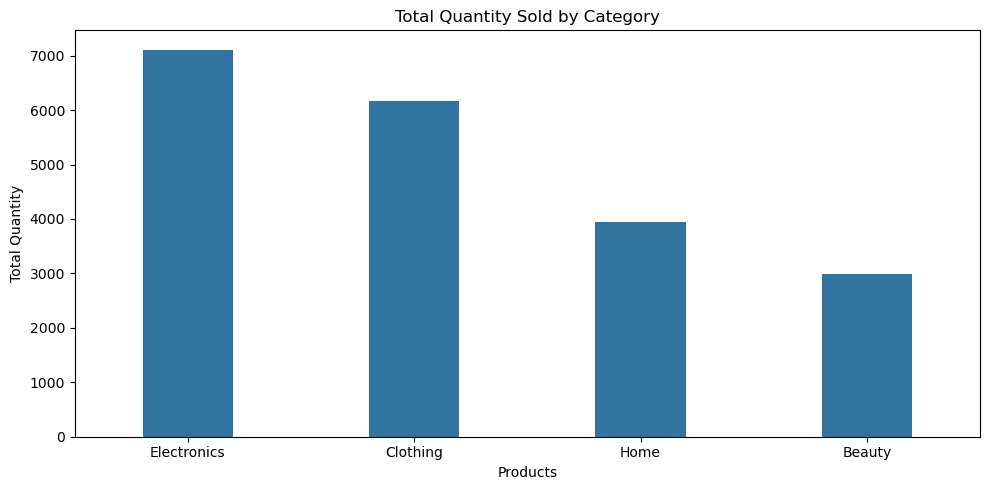

In [104]:
plt.figure(figsize=(10,5))
sns.barplot(x=quantity_by_category.index,y=quantity_by_category.values,width=0.4)
plt.title("Total Quantity Sold by Category")
plt.xlabel("Products")
plt.ylabel("Total Quantity")
plt.tight_layout()
plt.show()

#### Which category has the highest average customer rating?

In [100]:
rating_by_category=sales_data.groupby('product_category')['customer_rating'].mean().round(2)
rating_by_category

product_category
Beauty         3.01
Clothing       3.01
Electronics    2.95
Home           2.94
Name: customer_rating, dtype: float64

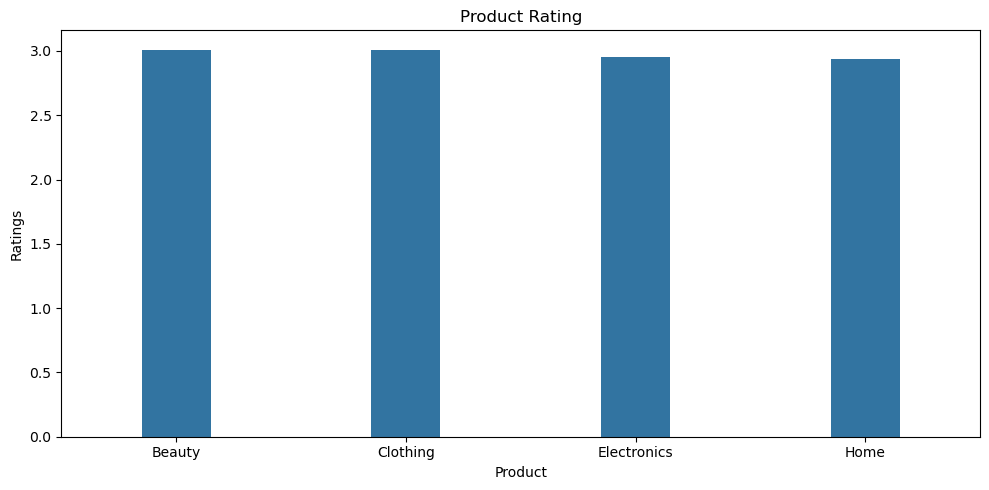

In [101]:
plt.figure(figsize=(10,5))
sns.barplot(x=rating_by_category.index,y=rating_by_category.values,width=0.3)
plt.title('Product Rating')
plt.xlabel('Product')
plt.ylabel('Ratings')
plt.tight_layout()
plt.show()

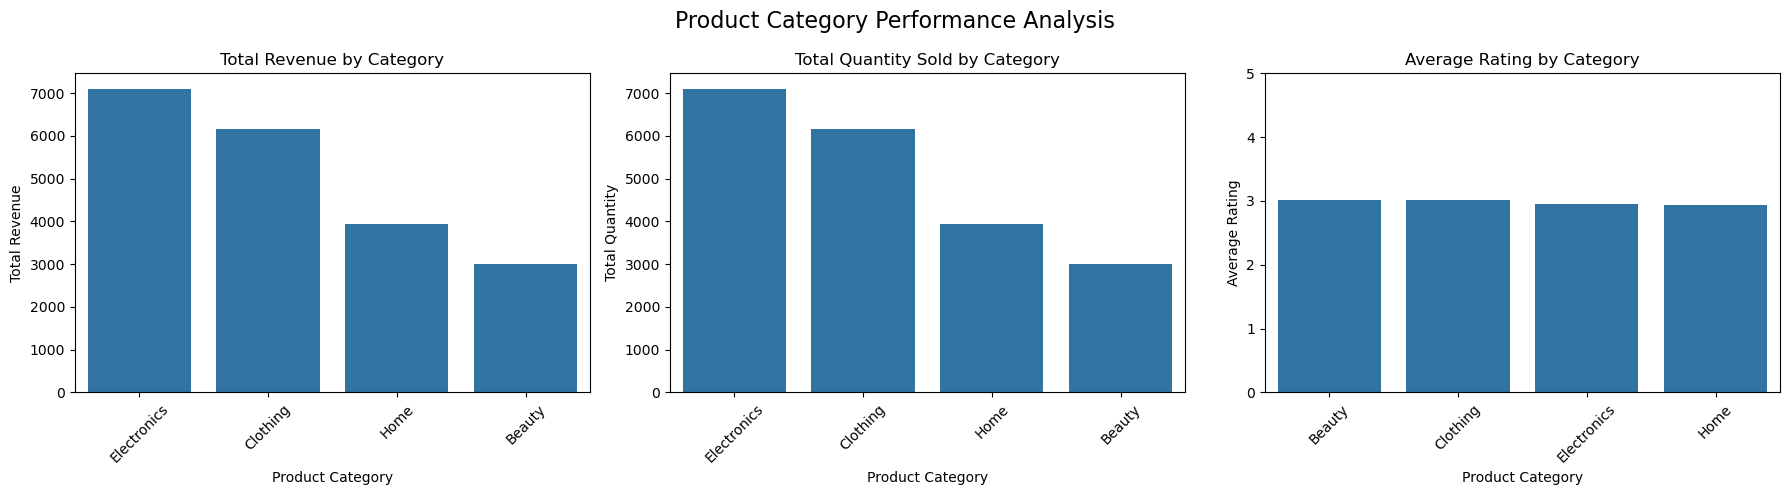

In [102]:

# Create 3 subplots in one row
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Total Revenue by Product Category
sns.barplot(
    x=revenue_by_category.index,
    y=revenue_by_category.values,
    ax=axes[0]
)

axes[0].set_title('Total Revenue by Category')
axes[0].set_xlabel('Product Category')
axes[0].set_ylabel('Total Revenue')
axes[0].tick_params(axis='x', rotation=45)


# 2. Total Quantity Sold by Product Category
sns.barplot(
    x=quantity_by_category.index,
    y=quantity_by_category.values,
    ax=axes[1]
)

axes[1].set_title('Total Quantity Sold by Category')
axes[1].set_xlabel('Product Category')
axes[1].set_ylabel('Total Quantity')
axes[1].tick_params(axis='x', rotation=45)


# 3. Average Customer Rating by Product Category
sns.barplot(
    x=rating_by_category.index,
    y=rating_by_category.values,
    ax=axes[2]
)

axes[2].set_title('Average Rating by Category')
axes[2].set_xlabel('Product Category')
axes[2].set_ylabel('Average Rating')
axes[2].set_ylim(0, 5)
axes[2].tick_params(axis='x', rotation=45)


# Main title and layout
fig.suptitle('Product Category Performance Analysis', fontsize=16)
plt.tight_layout()
plt.show()

### Regional Sales Analysis

#### Which region generates the highest revenue?

In [86]:
region_wise_revenue = sales_data.groupby('region')['revenue'].sum().sort_values(ascending=False)
print(f"Revenue By Region \n\n{region_wise_revenue}\n")

region_wise_orders = sales_data.groupby('region')['order_id'].nunique()
print(f"Order count By Region \n\n {region_wise_orders}\n")

region_wise_rating = sales_data.groupby('region')['customer_rating'].mean()
print(f"Rating By Region \n\n{region_wise_rating}\n")

Revenue By Region 

region
West     1345582.16
North    1281508.45
South    1246640.90
East     1236044.23
Name: revenue, dtype: float64

Order count By Region 

 region
East     1227
North    1276
South    1208
West     1289
Name: order_id, dtype: int64

Rating By Region 

region
East     2.973187
North    2.993182
South    2.967798
West     2.961521
Name: customer_rating, dtype: float64



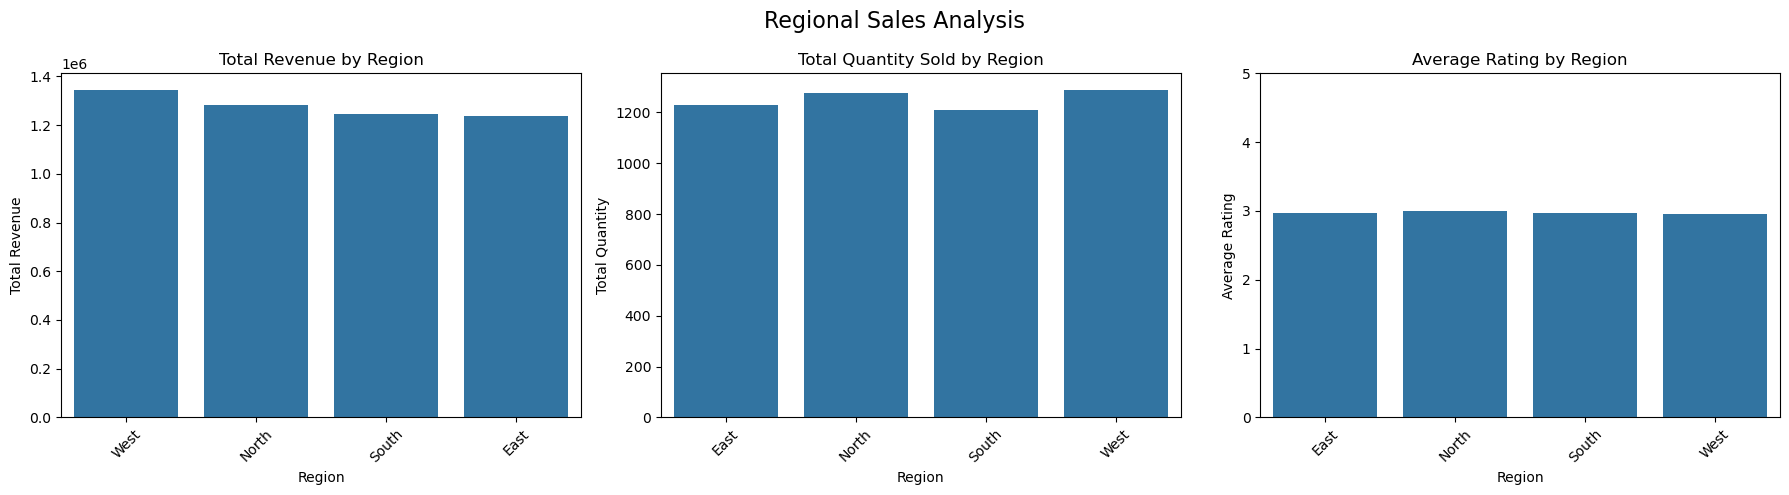

In [109]:

# Create 3 subplots in one row
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Total Revenue by Region
sns.barplot(
    x=region_wise_revenue.index,
    y=region_wise_revenue.values,
    ax=axes[0]
)

axes[0].set_title('Total Revenue by Region')
axes[0].set_xlabel('Region')
axes[0].set_ylabel('Total Revenue')
axes[0].tick_params(axis='x', rotation=45)


# 2. Number of Orders by Region
sns.barplot(
    x=region_wise_orders.index,
    y=region_wise_orders.values,
    ax=axes[1]
)

axes[1].set_title('Total Quantity Sold by Region')
axes[1].set_xlabel('Region')
axes[1].set_ylabel('Total Quantity')
axes[1].tick_params(axis='x', rotation=45)


# 3. Average Customer Rating by Product Category
sns.barplot(
    x=region_wise_rating.index,
    y=region_wise_rating.values,
    ax=axes[2]
)

axes[2].set_title('Average Rating by Region')
axes[2].set_xlabel('Region')
axes[2].set_ylabel('Average Rating')
axes[2].set_ylim(0, 5)
axes[2].tick_params(axis='x', rotation=45)


# Main title and layout
fig.suptitle('Regional Sales Analysis', fontsize=16)
plt.tight_layout()
plt.show()

The West region was the strongest performer in terms of revenue and quantity sold, while the North region achieved the highest customer rating. Although sales performance was relatively balanced across all regions, average customer ratings remained around 3 out of 5. The business should focus on maintaining strong sales in the West while improving customer satisfaction across all regions through better product quality, delivery services, and customer support.

In [111]:
%cd C:\Users\Dell\projects

C:\Users\Dell\projects


## main...origin/main
 M ecommerce_sales_analysis/ecommerce_sales_visualization.ipynb
